# Prévision des ventes d'un magasin (Rossmann)

Ce notebook prédit les ventes quotidiennes de magasins à partir de leur historique, du calendrier, des promotions et de leur environnement concurrentiel.

Il compare quatre approches :
1. une **baseline** simple (moyenne par magasin et jour de la semaine) ;
2. **XGBoost**, un modèle de boosting d'arbres ;
3. **LightGBM**, un autre modèle de boosting, plus rapide ;
4. **Random Forest**, un modèle de forêt aléatoire, de type différent.

**Fichiers nécessaires** dans le même dossier que ce notebook : `train.csv` et `store.csv` (compétition Rossmann Store Sales sur Kaggle).


## Étape 1 : importer les bibliothèques

On charge les outils de manipulation de données (pandas, numpy), de graphiques (matplotlib, seaborn), les deux modèles (XGBoost et LightGBM) et les métriques d'évaluation de scikit-learn.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import xgboost as xgb
import lightgbm as lgb
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from IPython.display import FileLink, display

print("Bibliothèques chargées")

Bibliothèques chargées


## Étape 2 : charger et fusionner les données

Le fichier `train.csv` contient les ventes jour par jour de chaque magasin. Le fichier `store.csv` contient les caractéristiques fixes de chaque magasin (type, assortiment, distance des concurrents, promotions à long terme). On les réunit sur la colonne `Store`.

In [2]:
train = pd.read_csv("train.csv", parse_dates=["Date"], low_memory=False)
store = pd.read_csv("store.csv")
df = train.merge(store, on="Store", how="left")
print(df.shape)
df.head()

(1017209, 18)


,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
0,1,5,2015-07-31,5263,555,1,1,0,1,c,a,1270.0,9.0,2008.0,0,NaN,NaN,NaN
1,2,5,2015-07-31,6064,625,1,1,0,1,a,a,570.0,11.0,2007.0,1,13.0,2010.0,"Jan,Apr,Jul,Oct"
2,3,5,2015-07-31,8314,821,1,1,0,1,a,a,14130.0,12.0,2006.0,1,14.0,2011.0,"Jan,Apr,Jul,Oct"
3,4,5,2015-07-31,13995,1498,1,1,0,1,c,c,620.0,9.0,2009.0,0,NaN,NaN,NaN
4,5,5,2015-07-31,4822,559,1,1,0,1,a,a,29910.0,4.0,2015.0,0,NaN,NaN,NaN


## Étape 3 : explorer les ventes

Avant de modéliser, on regarde la distribution des ventes et le nombre de jours fermés. Les jours où le magasin est fermé ont des ventes nulles : ils ne servent pas à apprendre la prévision.

In [3]:
print(df["Sales"].describe())
print("Jours fermés :", (df["Open"] == 0).sum())

count    1.017209e+06
mean     5.773819e+03
std      3.849926e+03
min      0.000000e+00
25%      3.727000e+03
50%      5.744000e+03
75%      7.856000e+03
max      4.155100e+04
Name: Sales, dtype: float64
Jours fermés : 172817


## Étape 4 : visualiser l'évolution des ventes et l'effet des promotions

Le premier graphique montre les ventes moyennes par jour sur toute la période : on y voit les pics hebdomadaires et les hausses de fin d'année. Le second compare les ventes moyennes avec et sans promotion.

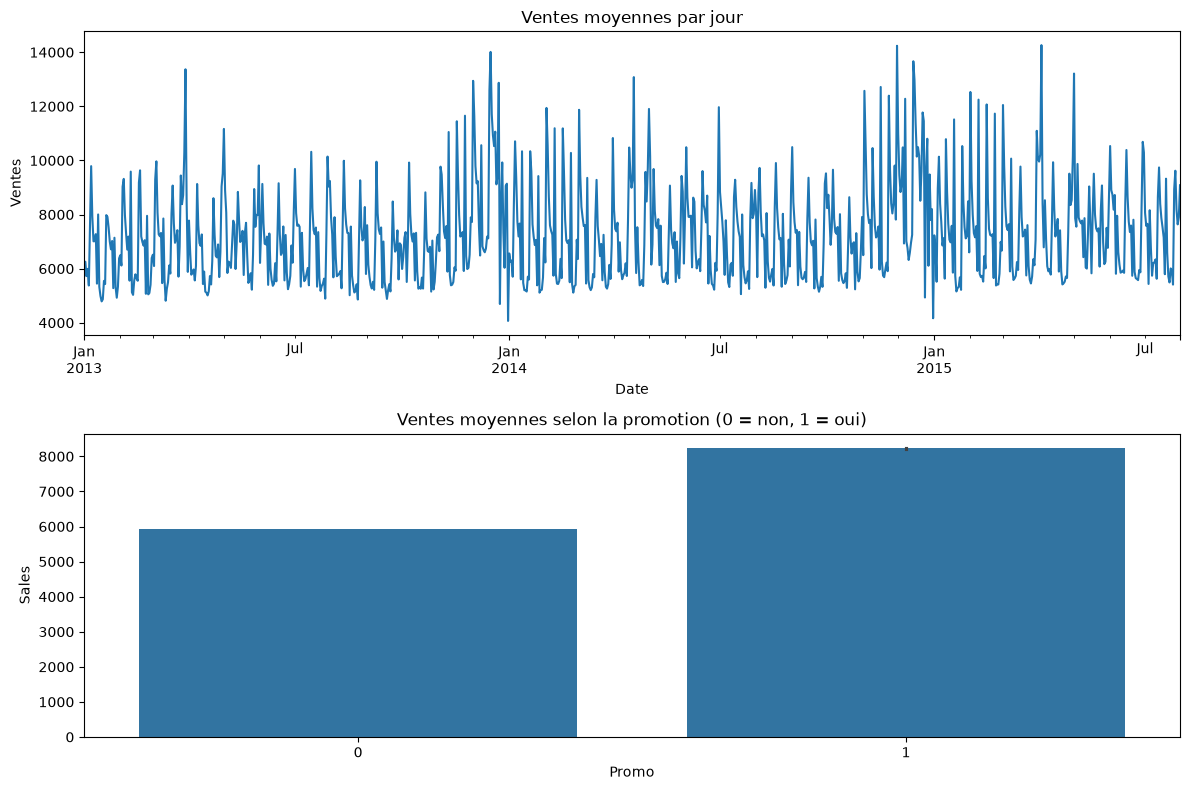

In [4]:
ouverts = df[df["Open"] == 1]
ventes_jour = ouverts.groupby("Date")["Sales"].mean()

fig, axes = plt.subplots(2, 1, figsize=(12, 8))
ventes_jour.plot(ax=axes[0], title="Ventes moyennes par jour")
axes[0].set_ylabel("Ventes")
sns.barplot(data=ouverts, x="Promo", y="Sales", ax=axes[1])
axes[1].set_title("Ventes moyennes selon la promotion (0 = non, 1 = oui)")
plt.tight_layout()
plt.show()

### Graphiques explicatifs : comprendre les ventes

Ces trois graphiques montrent les facteurs qui influencent les ventes avant toute modélisation.

- **Jour de la semaine** : les boîtes montrent la distribution des ventes pour chaque jour. Une boîte haute signifie que les ventes sont élevées ce jour-là.
- **Mois** : la moyenne mensuelle montre la saisonnalité, comme les hausses de fin d'année.
- **Type de magasin** : les magasins de types différents n'ont pas le même niveau de ventes. C'est pourquoi `StoreType` est une variable importante.

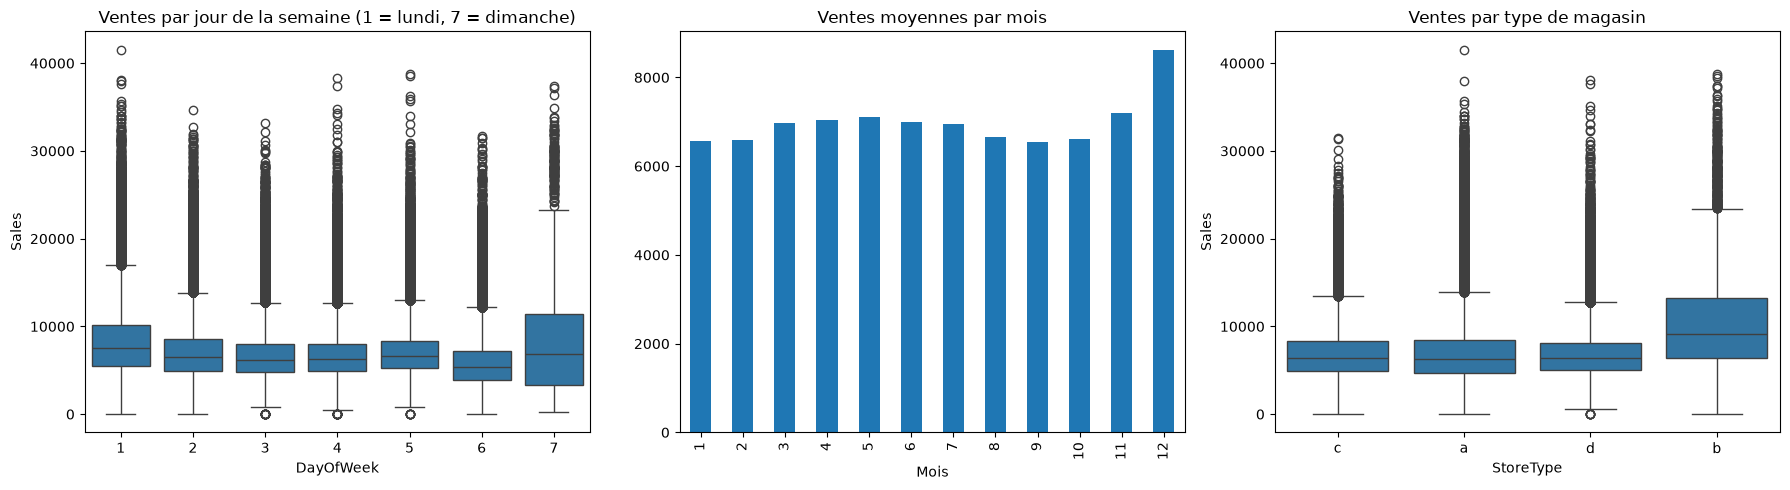

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.boxplot(data=ouverts, x="DayOfWeek", y="Sales", ax=axes[0])
axes[0].set_title("Ventes par jour de la semaine (1 = lundi, 7 = dimanche)")

mensuel = ouverts.groupby(ouverts["Date"].dt.month)["Sales"].mean()
mensuel.plot(kind="bar", ax=axes[1])
axes[1].set_title("Ventes moyennes par mois")
axes[1].set_xlabel("Mois")

sns.boxplot(data=ouverts, x="StoreType", y="Sales", ax=axes[2])
axes[2].set_title("Ventes par type de magasin")

plt.tight_layout()
plt.show()

## Étape 5 : nettoyer les données

On retire les jours fermés, puis on remplit les valeurs manquantes :
- `CompetitionDistance` : par la médiane (distance typique au concurrent le plus proche) ;
- les dates de début de concurrence et de promotion longue durée : par 0, qui signifie « pas de concurrent » ou « pas de promotion longue durée » ;
- `PromoInterval` : par la valeur `aucun`.

In [6]:
df = df[df["Open"] == 1].copy()

df["CompetitionDistance"] = df["CompetitionDistance"].fillna(df["CompetitionDistance"].median())
for col in ["CompetitionOpenSinceMonth", "CompetitionOpenSinceYear", "Promo2SinceWeek", "Promo2SinceYear"]:
    df[col] = df[col].fillna(0)
df["PromoInterval"] = df["PromoInterval"].fillna("aucun")

print(df.shape)

(844392, 18)


## Étape 6 : créer les variables de calendrier

Le modèle ne sait pas lire une date. On en extrait l'année, le mois, le jour du mois et le numéro de semaine dans l'année, pour capter la saisonnalité (fêtes, rentrée, été).

In [7]:
df["Year"] = df["Date"].dt.year
df["Month"] = df["Date"].dt.month
df["Day"] = df["Date"].dt.day
df["WeekOfYear"] = df["Date"].dt.isocalendar().week.astype(int)

print(df.shape)

(844392, 22)


## Étape 7 : encoder les variables catégorielles

Les modèles ne lisent que des nombres. On transforme les colonnes de texte (`StoreType`, `Assortment`, `StateHoliday`) en colonnes 0/1 : une colonne par modalité, sauf une modalité de référence supprimée (`drop_first=True`) pour éviter la redondance.

Cette cellule ne doit être exécutée qu'une seule fois. Relancée sur le même `df`, elle ne trouverait plus les colonnes d'origine.

In [8]:
df = pd.get_dummies(df, columns=["StoreType", "Assortment", "StateHoliday"], drop_first=True, dtype=int)

print(df.shape)
print(df.columns.tolist())

(844392, 27)
['Store', 'DayOfWeek', 'Date', 'Sales', 'Customers', 'Open', 'Promo', 'SchoolHoliday', 'CompetitionDistance', 'CompetitionOpenSinceMonth', 'CompetitionOpenSinceYear', 'Promo2', 'Promo2SinceWeek', 'Promo2SinceYear', 'PromoInterval', 'Year', 'Month', 'Day', 'WeekOfYear', 'StoreType_b', 'StoreType_c', 'StoreType_d', 'Assortment_b', 'Assortment_c', 'StateHoliday_a', 'StateHoliday_b', 'StateHoliday_c']


## Étape 8 : créer les variables de retard (lags)

Les ventes récentes d'un magasin donnent son niveau actuel. On ajoute trois variables, toutes calculées uniquement à partir du passé :
- `Sales_lag7` : les ventes d'il y a 7 jours (même jour de la semaine précédente) ;
- `Sales_roll7` : la moyenne des 7 jours précédents ;
- `Sales_dow_mean4` : la moyenne des 4 dernières occurrences du même jour de la semaine.

Les données sont triées par magasin puis par date, pour que les décalages suivent l'ordre du temps. Les premières lignes de chaque magasin n'ont pas d'historique : elles sont retirées.

Cette cellule ne doit être exécutée qu'une seule fois.

In [9]:
H = 42

pivot = df.pivot(index="Date", columns="Store", values="Sales")
pivot = pivot.reindex(pd.date_range(pivot.index.min(), pivot.index.max()))

decale = pivot.shift(H)
lag_df = decale
roll_df = decale.rolling(7, min_periods=1).mean()
moy8_df = decale.rolling(56, min_periods=1).mean()
moy13_df = decale.rolling(91, min_periods=1).mean()
moy26_df = decale.rolling(182, min_periods=1).mean()

parties = [pivot.shift(H + 7 * k) for k in range(4)]
somme = sum(p.fillna(0) for p in parties)
nombre = sum(p.notna().astype(int) for p in parties)
dow_df = somme / nombre.where(nombre > 0)

cles = pd.MultiIndex.from_arrays([df["Date"], df["Store"]])
tableaux = [
    ("Sales_lag42", lag_df),
    ("Sales_roll7_h42", roll_df),
    ("Sales_dow4_h42", dow_df),
    ("Sales_moy8s_h42", moy8_df),
    ("Sales_moy13s_h42", moy13_df),
    ("Sales_moy26s_h42", moy26_df),
]
for nom, tab in tableaux:
    valeurs = tab.stack()
    df[nom] = valeurs.reindex(cles).fillna(-1).values

print(df.shape)

(844392, 33)


## Étape : compteurs de jours avant et après les jours fériés

Les ventes changent autour des jours fériés, souvent la veille et le lendemain. Pour chaque jour, on calcule le nombre de jours avant le prochain jour férié et le nombre de jours depuis le dernier. Ces compteurs sont plafonnés à 14 jours. Ils ne dépendent que du calendrier, qui est connu à l'avance.

In [10]:
jours_ferie = pd.DatetimeIndex(train.loc[train["StateHoliday"].astype(str) != "0", "Date"].unique())
cal = pd.DatetimeIndex(pd.date_range(df["Date"].min(), df["Date"].max()))
marque = pd.Series(cal.where(cal.isin(jours_ferie)), index=cal)
serie_dates = pd.Series(cal, index=cal)
prochain = marque.bfill()
precedent = marque.ffill()

jours_avant = (prochain - serie_dates).dt.days.clip(upper=14).fillna(14)
jours_apres = (serie_dates - precedent).dt.days.clip(upper=14).fillna(14)

df["jours_avant_ferie"] = df["Date"].map(jours_avant)
df["jours_apres_ferie"] = df["Date"].map(jours_apres)

print(df[["jours_avant_ferie", "jours_apres_ferie"]].describe().round(2))

       jours_avant_ferie  jours_apres_ferie
count          844392.00          844392.00
mean               11.23              11.10
std                 4.40               4.47
min                 0.00               0.00
25%                 9.00               8.00
50%                14.00              14.00
75%                14.00              14.00
max                14.00              14.00


## Étape 9 : séparer l'entraînement et le test dans le temps

On ne mélange pas les dates au hasard : on entraîne sur tout le passé, et on teste sur les **6 dernières semaines**. C'est la seule façon honnête d'évaluer une prévision, car le modèle ne doit jamais voir le futur.

On exclut de la liste des variables la date, la cible (`Sales`), `Customers` (inconnu avant la fin de la journée de vente, donc il fuirait l'information), l'identifiant du magasin, `Open` (constant après le nettoyage) et `PromoInterval` (texte).

In [11]:
cutoff = df["Date"].max() - pd.Timedelta(weeks=6)
train_df = df[df["Date"] <= cutoff]
test_df = df[df["Date"] > cutoff]

exclure = ["Date", "Sales", "Customers", "Store", "Open", "PromoInterval"]
features = [c for c in df.columns if c not in exclure]

X_train, y_train = train_df[features], train_df["Sales"]
X_test, y_test = test_df[features], test_df["Sales"]

print(len(features), "variables")
print("Train :", X_train.shape, "| Test :", X_test.shape)

29 variables
Train : (804110, 29) | Test : (40282, 29)


## Étape 10 : définir la métrique RMSPE

Le RMSPE (Root Mean Square Percentage Error) est la métrique officielle de la compétition Rossmann. C'est une erreur relative : un écart de 500 ventes compte davantage sur un magasin qui vend 1 000 que sur un magasin qui vend 10 000. Les lignes où la vente réelle est nulle sont ignorées, car on ne peut pas diviser par zéro.

In [12]:
def rmspe(y_true, y_pred):
    mask = y_true != 0
    return np.sqrt(np.mean(((y_true[mask] - y_pred[mask]) / y_true[mask]) ** 2))

## Étape 11 : baseline

La baseline prédit la moyenne des ventes de chaque magasin pour chaque jour de la semaine, calculée sur l'entraînement. Elle sert de point de comparaison : un modèle qui ne la bat pas n'apporte rien.

In [13]:
moyennes = train_df.groupby(["Store", "DayOfWeek"])["Sales"].mean().rename("pred_baseline")
test_base = test_df[["Store", "DayOfWeek"]].merge(
    moyennes, left_on=["Store", "DayOfWeek"], right_index=True, how="left"
)
pred_base = test_base["pred_baseline"].fillna(train_df["Sales"].mean()).values

print(f"RMSPE baseline : {rmspe(y_test.values, pred_base):.4f}")

RMSPE baseline : 0.2356


## Étape 12 : entraîner XGBoost

XGBoost construit une suite d'arbres de décision, chacun corrigeant les erreurs du précédent. Les paramètres choisis sont des valeurs courantes de départ : 300 arbres, profondeur 8, taux d'apprentissage 0,05, et un échantillonnage de 80 % des lignes et des colonnes à chaque arbre pour limiter le surapprentissage.

## Étape : XGBoost avec la cible en logarithme

Les ventes ont une distribution étalée : les grands magasins dominent l'apprentissage. En entraînant le modèle sur le logarithme des ventes, il apprend des erreurs relatives, ce qui correspond davantage au RMSPE. Les prédictions sont ensuite reconvertie en ventes avec l'exponentielle.

Le modèle XGBoost d'origine (cible brute) est conservé pour comparaison.

In [14]:
xgb_log = xgb.XGBRegressor(
    n_estimators=300, max_depth=8, learning_rate=0.05,
    subsample=0.8, colsample_bytree=0.8, random_state=42
)
xgb_log.fit(X_train, np.log1p(y_train))
pred_xgb_log = np.expm1(xgb_log.predict(X_test))

print(f"RMSPE XGBoost (cible log) : {rmspe(y_test.values, pred_xgb_log):.4f}")

RMSPE XGBoost (cible log) : 0.1264


## Étape 13 : entraîner LightGBM

LightGBM est un autre modèle d'arbres de gradient. Il construit ses arbres feuille par feuille plutôt que niveau par niveau, ce qui le rend souvent plus rapide sur de grands jeux de données. On utilise des paramètres proches de XGBoost pour que la comparaison reste équitable.

In [ ]:
lgb_model = lgb.LGBMRegressor(
    n_estimators=300, learning_rate=0.05, num_leaves=127,
    subsample=0.8, colsample_bytree=0.8, random_state=42, verbose=-1
)
lgb_model.fit(X_train, y_train)
pred_lgb = lgb_model.predict(X_test)

print(f"RMSPE LightGBM : {rmspe(y_test.values, pred_lgb):.4f}")

In [ ]:
pred_ens = (pred_xgb_log + pred_lgb) / 2

print(f"RMSPE moyenne XGBoost log + LightGBM : {rmspe(y_test.values, pred_ens):.4f}")

## Étape 14 : entraîner une forêt aléatoire (Random Forest)

La forêt aléatoire est un troisième type de modèle, différent des deux précédents. Au lieu de corriger les erreurs des arbres les uns après les autres (boosting), elle construit de nombreux arbres indépendants, chacun sur un échantillon aléatoire des données, puis fait la moyenne de leurs prédictions. Elle est plus robuste au bruit, mais souvent un peu moins précise que le boosting.

Pour limiter le temps de calcul, chaque arbre n'utilise que 30 % des lignes d'entraînement.

In [ ]:
from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(
    n_estimators=100, max_depth=14, min_samples_leaf=5,
    max_samples=0.3, n_jobs=-1, random_state=42
)
rf_model.fit(X_train, y_train)
pred_rf = rf_model.predict(X_test)

print(f"RMSPE Random Forest : {rmspe(y_test.values, pred_rf):.4f}")

## Étape 15 : comparer les modèles

Le tableau réunit quatre métriques pour chaque approche :
- **RMSPE** : erreur relative (métrique de la compétition, plus petit = meilleur) ;
- **RMSE** : erreur quadratique moyenne, en nombre de ventes, qui pénalise fortement les grosses erreurs ;
- **MAE** : erreur absolue moyenne, en nombre de ventes, plus facile à interpréter ;
- **R²** : part de la variation des ventes expliquée (1 = parfait, 0 = équivalent à la moyenne).

In [ ]:
resultats = []
for nom, p in [("Baseline", pred_base), ("XGBoost log", pred_xgb_log), ("LightGBM", pred_lgb), ("Random Forest", pred_rf), ("XGBoost log + LightGBM", pred_ens)]:
    resultats.append({
        "Modèle": nom,
        "RMSPE": round(rmspe(y_test.values, p), 4),
        "RMSE": round(np.sqrt(mean_squared_error(y_test, p)), 1),
        "MAE": round(mean_absolute_error(y_test, p), 1),
        "R²": round(r2_score(y_test, p), 4),
    })

tableau = pd.DataFrame(resultats).set_index("Modèle")
tableau

### Graphiques explicatifs : comparer les modèles et les prévisions

Le premier graphique montre le RMSPE de chaque modèle : plus la barre est basse, plus le modèle est précis.

Le second montre, pour un magasin, les ventes réelles (bleu) et les ventes prédites par XGBoost (orange). Si les deux courbes suivent les mêmes hausses et baisses, le modèle a bien appris le rythme hebdomadaire du magasin. Un écart systématique révèle un biais.

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(18, 5))

tableau["RMSPE"].plot(kind="bar", ax=axes[0], color="steelblue")
axes[0].set_title("RMSPE par modèle (plus bas = meilleur)")
axes[0].set_ylabel("RMSPE")
axes[0].tick_params(axis="x", rotation=0)

ex = test_df[["Date", "Store", "Sales"]].copy()
ex["pred"] = pred_ens
ex = ex[ex["Store"] == 1].sort_values("Date")
axes[1].plot(ex["Date"], ex["Sales"], label="Réel")
axes[1].plot(ex["Date"], ex["pred"], label="Prédit (XGBoost)")
axes[1].set_title("Magasin 1 : réel contre prédit sur la période de test")
axes[1].legend()
axes[1].tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

## Étape 16 : analyser l'erreur du meilleur modèle

On garde le modèle au RMSPE le plus bas et on regarde où il se trompe : par jour de la semaine (pour repérer les jours difficiles), puis par magasin (pour repérer les cas particuliers).

Un RMSPE très élevé pour un magasin peut venir de ventes réelles très faibles, car elles figurent au dénominateur. Dans ce cas, la MAE est un indicateur plus fiable.

In [ ]:
meilleur = tableau["RMSPE"].idxmin()
predictions = {"Baseline": pred_base, "XGBoost log": pred_xgb_log, "LightGBM": pred_lgb, "Random Forest": pred_rf, "XGBoost log + LightGBM": pred_ens}
pred_meilleur = predictions[meilleur]
print("Meilleur modèle selon le RMSPE :", meilleur)

res = test_df[["Store", "DayOfWeek", "Sales"]].copy()
res["pred"] = pred_meilleur
res["erreur_abs"] = (res["Sales"] - res["pred"]).abs()
res["erreur_pct"] = res["erreur_abs"] / res["Sales"].where(res["Sales"] != 0)

print("\nErreur moyenne par jour de la semaine :")
print(res.groupby("DayOfWeek")[["erreur_abs", "erreur_pct"]].mean().round(3))

print("\nMagasins les plus difficiles (RMSPE) :")
pires = res.groupby("Store").apply(
    lambda g: rmspe(g["Sales"].values, g["pred"].values)
).sort_values(ascending=False).head(5)
print(pires.round(4))

## Étape 17 : importance des variables (XGBoost)

Ce graphique montre les variables que XGBoost utilise le plus pour prédire. Il est enregistré en PNG et peut être téléchargé en cliquant sur le lien affiché sous la cellule.

In [ ]:
imp = pd.Series(xgb_log.feature_importances_, index=features).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(8, 5))
imp.head(10).plot(kind="barh", ax=ax, title="Variables les plus importantes (XGBoost)")
ax.invert_yaxis()
ax.set_xlabel("Importance")
plt.tight_layout()
plt.savefig("importance_variables.png", dpi=150, bbox_inches="tight")
plt.show()

display(FileLink("importance_variables.png"))

## Conclusion

Ce travail prédit les ventes quotidiennes de 1 115 magasins pour les six dernières semaines de données, à partir de leur historique, de leur calendrier, des promotions et de leur environnement concurrentiel.

**Résultats**

La baseline, qui prédit la moyenne des ventes par magasin et jour de la semaine, atteint un RMSPE de 0,2352 et un R² de 0,70. Elle sert de point de référence : tous les modèles plus complexes doivent la battre nettement.

Les modèles de boosting réduisent fortement l'erreur. XGBoost obtient le meilleur score du notebook, avec un RMSPE de 0,1248, un RMSE de 883 ventes, un MAE de 606 ventes et un R² de 0,92. LightGBM est très proche (RMSPE de 0,1297), ce qui montre que le gain vient surtout des variables et de la méthode de boosting, et moins du choix de la bibliothèque.

La forêt aléatoire apporte une comparaison avec une famille de modèles différente. Son score figure dans le tableau de l'étape 15. Le modèle retenu est celui qui a le RMSPE le plus bas.

**Facteurs qui expliquent les ventes**

Les variables les plus importantes sont le type de magasin, les promotions et la distance au concurrent le plus proche. Les retards de ventes (ventes de la semaine précédente, moyenne du même jour de la semaine) aident aussi nettement le modèle. Le samedi et le dimanche sont les jours les moins bien prédits.

**Limites**

Les variables de retard utilisent les ventes réelles des jours précédents, y compris dans la période de test. Les scores correspondent donc à une prévision à un jour près, et non à une prévision de six semaines sans information récente. Une évaluation honnête sur six semaines, avec des retards calculés uniquement à partir de l'entraînement, donnerait des scores moins bons.

Le magasin 292 reste très mal prédit (RMSPE supérieur à 1), car ses ventes réelles sont souvent très faibles. Il faudrait l'analyser à part ou le retirer de l'évaluation, en le justifiant.

**Pistes d'amélioration**

Évaluer les modèles sur plusieurs périodes de test pour vérifier la stabilité des résultats, tester l'effet de chaque variable de retard séparément, et traiter les magasins à faibles ventes.